# German English Translation GRU vs Transformer

**Question:** How do fresh context-vector GRU and causally masked encoder-decoder Transformer models compare under the same translation data/epoch budget?

Kerem Ozcan | IBM AI Engineering portfolio | Prepared with AI assistance

Original experiment code developed from course concepts. This notebook contains no IBM assessment solutions or supplied course model predictions.

## Design and evaluation boundary

Official Multi30k train/validation/test-2016 sentence files, pinned to repository revision a3d2e0d26b56f3846f66a952536ffed4e401d05a. Keep at most 48 tokens per side; remove repeated normalized German source sentences with held-out priority. Fit both vocabularies on retained training data only. Share initial embedding tensors, training order, batch size64, learning rate0.0005 and six epochs. Other architecture/parameter/compute differences remain. Validation token NLL selects checkpoints; generate the complete retained test set greedily and compute case-insensitive corpus SacreBLEU (13a), not a hand-picked sentence score.

One seed, short-caption domain, capped vocabularies and six epochs. Parameter counts differ, so an isolated effect of attention is not established. BLEU is a limited automatic metric, not a human translation-quality judgment.

## Runtime

Kaggle internet is required for provider-hosted inputs/models. Local verification uses already installed isolated environments. `SECOND_BATCH_FULL=0` selects a small local correctness pilot for the neural projects; the published Kaggle version uses the documented full experiment budget. Data and weights stay in scratch storage; only JSON evidence, plots and notebook outputs are exported.

In [1]:
import os
import sys
import subprocess
import gzip
import shutil
from pathlib import Path
os.environ["USE_TF"]="0"
os.environ["TOKENIZERS_PARALLELISM"]="false"
os.environ["OMP_NUM_THREADS"]="1"
ON_KAGGLE=Path("/kaggle/working").is_dir()
if ON_KAGGLE and True:
    subprocess.run([sys.executable,"-m","pip","install","-q",*['sacrebleu==2.5.1']],check=True)
import matplotlib.pyplot as plt
import numpy as np
import json
FULL_RUN=os.environ.get("SECOND_BATCH_FULL","1")=="1"
LOCAL_ROOT=next((p for p in [Path.cwd(),*Path.cwd().parents] if (p/"provenance/source-manifest.json").exists()),Path.cwd())
WORK=Path("/kaggle/working") if ON_KAGGLE else LOCAL_ROOT/".lab-cache/second-batch-notebooks"/'translation'/"exports"
SCRATCH=Path("/kaggle/temp/ibm-second-batch") if ON_KAGGLE else LOCAL_ROOT/".lab-cache/second-batch-notebooks"/'translation'/"scratch"
WORK.mkdir(parents=True,exist_ok=True);SCRATCH.mkdir(parents=True,exist_ok=True)
DATA_ROOT=SCRATCH/"inputs" if ON_KAGGLE else LOCAL_ROOT/".lab-cache/second-batch-data"
RUN_OUTPUT=SCRATCH/'translation';OUTPUT=WORK/'translation';OUTPUT.mkdir(parents=True,exist_ok=True)


Matplotlib is building the font cache; this may take a moment.


## Inputs and provenance

[Multi30k dataset and research references](https://github.com/multi30k/dataset). Text is downloaded from that provider at a pinned revision; the dataset is not bundled or assigned a new license. Concepts studied in the IBM sequence-to-sequence/Transformer courses; no supplied course weights or assessment solutions are included.

Provider downloads must match the pinned SHA-256 values below. Model weights are fetched from the original provider; no submitted lab checkpoint is reused.

In [2]:
"""Small, standalone data acquisition helpers embedded in the Kaggle releases."""

import hashlib
import shutil
import tarfile
import urllib.request
from pathlib import Path


def verified_download(url: str, target: Path, expected_sha256: str) -> Path:
    """Download to a temporary file and accept only the reviewed dataset bytes."""
    target.parent.mkdir(parents=True, exist_ok=True)
    if target.is_file() and hashlib.sha256(target.read_bytes()).hexdigest() == expected_sha256:
        return target
    temporary = target.with_suffix(target.suffix + ".download")
    try:
        with urllib.request.urlopen(url, timeout=60) as response, temporary.open("wb") as stream:
            shutil.copyfileobj(response, stream)
        if hashlib.sha256(temporary.read_bytes()).hexdigest() != expected_sha256:
            raise ValueError("Downloaded data changed; review its provenance before running.")
        temporary.replace(target)
    finally:
        temporary.unlink(missing_ok=True)
    return target


def unpack_regular_tar(archive: Path, destination: Path) -> None:
    """Reject links, special files and traversal before writing any archive member."""
    root = destination.resolve()
    with tarfile.open(archive) as bundle:
        members = bundle.getmembers()
        for member in members:
            path = root / member.name
            if (
                Path(member.name).is_absolute()
                or not path.resolve().is_relative_to(root)
                or not (member.isfile() or member.isdir())
            ):
                raise ValueError("Unsafe dataset archive member.")
        for member in members:
            path = root / member.name
            if member.isdir():
                path.mkdir(parents=True, exist_ok=True)
            else:
                path.parent.mkdir(parents=True, exist_ok=True)
                with bundle.extractfile(member) as source, path.open("wb") as target:
                    shutil.copyfileobj(source, target)


In [3]:
INPUTS=[{'file': 'translation/train.de.gz', 'url': 'https://raw.githubusercontent.com/multi30k/dataset/a3d2e0d26b56f3846f66a952536ffed4e401d05a/data/task1/raw/train.de.gz', 'sha256': '726e39b2fa9eb9ffb6dc763fb35a179f80fae06ffc5d28b6ace5faa883de28a6', 'bytes': 637044}, {'file': 'translation/train.en.gz', 'url': 'https://raw.githubusercontent.com/multi30k/dataset/a3d2e0d26b56f3846f66a952536ffed4e401d05a/data/task1/raw/train.en.gz', 'sha256': 'd79cfa999dd4c51d2cb42499b6796d5a882c3a8a961923c25a898c90f8bbd56f', 'bytes': 568929}, {'file': 'translation/val.de.gz', 'url': 'https://raw.githubusercontent.com/multi30k/dataset/a3d2e0d26b56f3846f66a952536ffed4e401d05a/data/task1/raw/val.de.gz', 'sha256': 'f0cba2f995189cf5770f29a8a9a537a3ad3f51657ad873405082ff6863a5e75a', 'bytes': 24681}, {'file': 'translation/val.en.gz', 'url': 'https://raw.githubusercontent.com/multi30k/dataset/a3d2e0d26b56f3846f66a952536ffed4e401d05a/data/task1/raw/val.en.gz', 'sha256': '14f7d25ddd868909a9213e361768460edcacdd6ab9d1e77b92560dc10c10dc28', 'bytes': 21650}, {'file': 'translation/test_2016_flickr.de.gz', 'url': 'https://raw.githubusercontent.com/multi30k/dataset/a3d2e0d26b56f3846f66a952536ffed4e401d05a/data/task1/raw/test_2016_flickr.de.gz', 'sha256': '9204244e408ccb38d2a55cfcd344df15005fc42a07a6e55ca6c52b6ababb8cc8', 'bytes': 22890}, {'file': 'translation/test_2016_flickr.en.gz', 'url': 'https://raw.githubusercontent.com/multi30k/dataset/a3d2e0d26b56f3846f66a952536ffed4e401d05a/data/task1/raw/test_2016_flickr.en.gz', 'sha256': '611d361c6334bc7246101d48097c13cf5c4413c5befc793cc629934359d532d9', 'bytes': 21077}]
for entry in INPUTS:
    path=verified_download(entry["url"],DATA_ROOT/entry["file"],entry["sha256"])
    if path.suffix==".gz":
        with gzip.open(path,"rb") as source,path.with_suffix("").open("wb") as target:
            shutil.copyfileobj(source,target)


## Standalone implementation

Expand this cell to inspect data partitions, actual sample accounting, training and selected-checkpoint reload checks.

In [4]:
"""Shared provenance and evaluation helpers for the selected portfolio projects."""

from __future__ import annotations

import hashlib
import importlib.metadata
import json
import platform
import random
from collections import Counter, defaultdict
from datetime import UTC, datetime
from pathlib import Path


def file_sha256(path: Path) -> str:
    """Hash an input/checkpoint without reading the entire file into memory."""
    digest = hashlib.sha256()
    with path.open("rb") as stream:
        for block in iter(lambda: stream.read(1024 * 1024), b""):
            digest.update(block)
    return digest.hexdigest()


def write_json(path: Path, value: dict | list) -> None:
    """Publish a complete JSON artifact atomically."""
    path.parent.mkdir(parents=True, exist_ok=True)
    temporary = path.with_suffix(path.suffix + ".tmp")
    temporary.write_text(
        json.dumps(value, indent=2, ensure_ascii=False, allow_nan=False) + "\n", encoding="utf-8"
    )
    temporary.replace(path)


def runtime(packages: list[str]) -> dict:
    """Capture versions without collecting environment variables or host paths."""
    return {
        "utc": datetime.now(UTC).isoformat(),
        "python": platform.python_version(),
        "platform": platform.system(),
        "packages": {name: importlib.metadata.version(name) for name in packages},
    }


def source_identity(project_file: str | None, embedded_digest: str | None = None) -> dict:
    """Bind module runs and generated notebooks to their authored source files."""
    project_digest = file_sha256(Path(project_file)) if project_file else embedded_digest
    common_digest = (
        file_sha256(Path(__file__))
        if "__file__" in globals()
        else globals().get("COMMON_SOURCE_SHA256")
    )
    if not project_digest or not common_digest:
        raise ValueError("Project source identity is missing.")
    return {"project_sha256": project_digest, "common_sha256": common_digest}


def index_images(
    root: Path, class_names: list[str], directories: dict[str, str] | None = None
) -> list[dict]:
    """Index decoded RGB content as well as bytes, retaining only relative filenames."""
    from PIL import Image, ImageOps

    rows = []
    directories = directories or {"unsplit": "."}
    for role, directory in directories.items():
        for label, name in enumerate(class_names):
            folder = root / directory / name
            if not folder.is_dir():
                raise ValueError(f"Missing image class directory: {directory}/{name}")
            for path in sorted(folder.rglob("*")):
                if path.suffix.lower() not in {".jpg", ".jpeg", ".png"}:
                    continue
                with Image.open(path) as original:
                    image = ImageOps.exif_transpose(original).convert("RGB")
                    pixels = str(image.size).encode() + image.tobytes()
                rows.append(
                    {
                        "file": path.relative_to(root).as_posix(),
                        "label": label,
                        "role": role,
                        "file_sha256": file_sha256(path),
                        "pixel_sha256": hashlib.sha256(pixels).hexdigest(),
                    }
                )
    if not rows:
        raise ValueError("No images found.")
    return rows


def clean_image_splits(rows: list[dict]) -> tuple[list[dict], list[dict]]:
    """Remove exact duplicates and conflicting labels, preserving held-out copies first."""
    groups = defaultdict(list)
    for row in rows:
        groups[row["pixel_sha256"]].append(row)
    retained, removed = [], []
    priority = {"test": 0, "validation": 1, "train": 2}
    for group in groups.values():
        if len({row["label"] for row in group}) > 1:
            removed.extend(
                {"file": row["file"], "reason": "conflicting_pixel_labels"} for row in group
            )
            continue
        ordered = sorted(group, key=lambda row: (priority[row["role"]], row["file"]))
        retained.append(ordered[0])
        removed.extend(
            {"file": row["file"], "reason": "exact_pixel_duplicate"} for row in ordered[1:]
        )
    return sorted(retained, key=lambda row: row["file"]), removed


def balanced_subset(rows: list[dict], per_class: int | None, seed: int) -> list[dict]:
    """Select a reproducible pilot without changing the complete split manifest."""
    if per_class is None:
        return rows
    rng = random.Random(seed)
    result = []
    for label in sorted({row["label"] for row in rows}):
        group = sorted((row for row in rows if row["label"] == label), key=lambda row: row["file"])
        rng.shuffle(group)
        result.extend(group[:per_class])
    return sorted(result, key=lambda row: row["file"])


def split_counts(rows: list[dict]) -> dict:
    """Describe the actual records, including class support."""
    return {
        role: dict(Counter(str(row["label"]) for row in rows if row["role"] == role))
        for role in ["train", "validation", "test"]
    }


def classification_metrics(labels: list[int], probabilities: list[float]) -> dict:
    """Evaluate exactly the predictions supplied, never the size of an upstream dataset."""
    import numpy as np
    from sklearn.metrics import (
        accuracy_score,
        classification_report,
        confusion_matrix,
        f1_score,
        roc_auc_score,
    )

    if not labels or len(labels) != len(probabilities):
        raise ValueError("Predictions and labels must have the same nonzero length.")
    probabilities = np.asarray(probabilities)
    if not np.isfinite(probabilities).all() or ((probabilities < 0) | (probabilities > 1)).any():
        raise ValueError("Expected finite probabilities in [0, 1].")
    predicted = (probabilities >= 0.5).astype(int)
    return {
        "samples": len(labels),
        "accuracy": float(accuracy_score(labels, predicted)),
        "macro_f1": float(
            f1_score(labels, predicted, labels=[0, 1], average="macro", zero_division=0)
        ),
        "roc_auc": float(roc_auc_score(labels, probabilities)) if len(set(labels)) == 2 else None,
        "confusion_matrix": confusion_matrix(labels, predicted, labels=[0, 1]).tolist(),
        "per_class": classification_report(
            labels, predicted, labels=[0, 1], output_dict=True, zero_division=0
        ),
    }

COMMON_SOURCE_SHA256='ded7059d91e2123ef7bc9be2823a1d220d905041f45b9dbe83bac59d27547853'
PROJECT_SOURCE_SHA256='0a1a42aec67caecd549b1614ce19655b5f54038f7683ca5d388fae85f022f8e6'
"""Compare fresh German-to-English models using the same paired data and epoch budget."""


import collections
import hashlib
import math
import random
import re
import time
from pathlib import Path

import torch
from torch import nn
from torch.utils.data import DataLoader


PAD, BOS, EOS, UNK = 0, 1, 2, 3


def tokenize(text: str) -> list[str]:
    """Use the same deterministic Unicode word/punctuation tokenizer in both models."""
    return re.findall(r"\w+|[^\w\s]", text.casefold())


def load_pairs(root: Path, maximum_tokens: int = 48) -> tuple[dict, dict]:
    """Reserve official splits and exclude repeated normalized source sentences across roles."""
    parts, seen, audit = {}, set(), {"excluded": collections.Counter()}
    for role, stem in [("test", "test_2016_flickr"), ("validation", "val"), ("train", "train")]:
        german = (root / f"{stem}.de").read_text(encoding="utf-8").splitlines()
        english = (root / f"{stem}.en").read_text(encoding="utf-8").splitlines()
        if len(german) != len(english):
            raise ValueError("Parallel files have different lengths.")
        rows = []
        for source, reference in zip(german, english, strict=True):
            src, tgt = tokenize(source), tokenize(reference)
            group = hashlib.sha256(" ".join(src).encode()).hexdigest()
            if not src or not tgt or max(len(src), len(tgt)) > maximum_tokens:
                audit["excluded"]["empty_or_over_length"] += 1
                continue
            if group in seen:
                audit["excluded"]["repeated_source_sentence"] += 1
                continue
            seen.add(group)
            rows.append(
                {"id": group, "source": source, "reference": reference, "src": src, "tgt": tgt}
            )
        if not rows:
            raise ValueError(f"No retained {role} pairs.")
        parts[role] = rows
    audit["excluded"] = dict(audit["excluded"])
    audit["input_files"] = {p.name: file_sha256(p) for p in root.glob("*.de")} | {
        p.name: file_sha256(p) for p in root.glob("*.en")
    }
    return parts, audit


def vocabulary(rows: list[dict], key: str, cap: int = 8000) -> tuple[dict, list]:
    """Fit token indices exclusively on the training records used in this run."""
    counts = collections.Counter(token for row in rows for token in row[key])
    tokens = ["<pad>", "<bos>", "<eos>", "<unk>"] + [
        word for word, _ in sorted(counts.items(), key=lambda pair: (-pair[1], pair[0]))[: cap - 4]
    ]
    return {word: i for i, word in enumerate(tokens)}, tokens


def batchify(rows: list[dict], source_vocab: dict, target_vocab: dict):
    arrays = []
    for key, vocab in [("src", source_vocab), ("tgt", target_vocab)]:
        values = [
            torch.tensor([BOS] + [vocab.get(t, UNK) for t in row[key]] + [EOS]) for row in rows
        ]
        arrays.append(nn.utils.rnn.pad_sequence(values, batch_first=True, padding_value=PAD))
    return arrays[0], arrays[1], rows


class RecurrentTranslator(nn.Module):
    """A context-vector GRU encoder/decoder with parallel teacher-forced training."""

    def __init__(self, source_size: int, target_size: int, width: int = 128):
        super().__init__()
        self.source_embedding = nn.Embedding(source_size, width, padding_idx=PAD)
        self.target_embedding = nn.Embedding(target_size, width, padding_idx=PAD)
        self.encoder = nn.GRU(width, width, batch_first=True)
        self.decoder = nn.GRU(width * 2, width, batch_first=True)
        self.head = nn.Linear(width, target_size)

    def forward(self, source, target):
        lengths = source.ne(PAD).sum(1).cpu()
        embedded = nn.utils.rnn.pack_padded_sequence(
            self.source_embedding(source), lengths, batch_first=True, enforce_sorted=False
        )
        _, context = self.encoder(embedded)
        target_emb = self.target_embedding(target)
        repeated = context[-1].unsqueeze(1).expand(-1, target.shape[1], -1)
        output, _ = self.decoder(torch.cat([target_emb, repeated], -1), context)
        return self.head(output)


class TransformerTranslator(nn.Module):
    """A causal two-layer encoder/decoder; padding is masked in attention."""

    def __init__(self, source_size: int, target_size: int, width: int = 128):
        super().__init__()
        self.source_embedding = nn.Embedding(source_size, width, padding_idx=PAD)
        self.target_embedding = nn.Embedding(target_size, width, padding_idx=PAD)
        self.transformer = nn.Transformer(
            d_model=width,
            nhead=4,
            num_encoder_layers=2,
            num_decoder_layers=2,
            dim_feedforward=256,
            dropout=0.1,
            batch_first=True,
        )
        positions = torch.arange(64)[:, None]
        scale = torch.exp(torch.arange(0, width, 2) * (-math.log(10000.0) / width))
        encoding = torch.zeros(64, width)
        encoding[:, 0::2] = torch.sin(positions * scale)
        encoding[:, 1::2] = torch.cos(positions * scale)
        self.register_buffer("positions", encoding)
        self.head = nn.Linear(width, target_size)
        self.width = width

    def forward(self, source, target):
        mask = torch.ones(
            target.shape[1], target.shape[1], device=target.device, dtype=torch.bool
        ).triu(1)
        src = (
            self.source_embedding(source) * math.sqrt(self.width)
            + self.positions[: source.shape[1]]
        )
        tgt = (
            self.target_embedding(target) * math.sqrt(self.width)
            + self.positions[: target.shape[1]]
        )
        output = self.transformer(
            src,
            tgt,
            tgt_mask=mask,
            src_key_padding_mask=source.eq(PAD),
            tgt_key_padding_mask=target.eq(PAD),
            memory_key_padding_mask=source.eq(PAD),
        )
        return self.head(output)


def token_loss(model, loader, device) -> dict:
    """Weight reference loss by actual non-padding next-token targets."""
    model.eval()
    total = 0.0
    count = 0
    with torch.no_grad():
        for src, tgt, _ in loader:
            src, tgt = src.to(device), tgt.to(device)
            output = model(src, tgt[:, :-1])
            total += float(
                nn.functional.cross_entropy(
                    output.reshape(-1, output.shape[-1]),
                    tgt[:, 1:].reshape(-1),
                    ignore_index=PAD,
                    reduction="sum",
                )
            )
            count += int(tgt[:, 1:].ne(PAD).sum())
    return {"nll": total / count, "tokens": count}


def translations(model, loader, device, words: list[str]) -> tuple[list[str], list[dict]]:
    """Decode freely, with identical greedy settings and a 49-token generation cap."""
    model.eval()
    hypotheses = []
    records = []
    with torch.no_grad():
        for src, _, rows in loader:
            src = src.to(device)
            generated = torch.full((len(src), 1), BOS, device=device, dtype=torch.long)
            finished = torch.zeros(len(src), dtype=torch.bool, device=device)
            for _ in range(49):
                output = model(src, generated)[:, -1].argmax(-1)
                output = torch.where(finished, torch.full_like(output, EOS), output)
                generated = torch.cat([generated, output[:, None]], 1)
                finished |= output.eq(EOS)
                if bool(finished.all()):
                    break
            for row, ids in zip(rows, generated[:, 1:].cpu().tolist(), strict=True):
                if EOS in ids:
                    ids = ids[: ids.index(EOS)]
                text = " ".join(words[i] for i in ids if i not in [PAD, BOS])
                hypotheses.append(text)
                records.append({"id": row["id"], "prediction": text})
    return hypotheses, records


def run(
    data_root: Path, output: Path, *, full: bool = False, seed: int = 42, epochs: int = 6
) -> dict:
    """Use fresh matched-budget models and reserve test generation until checkpoint selection."""
    from functools import partial

    from sacrebleu.metrics import BLEU

    torch.set_num_threads(1)
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    parts, audit = load_pairs(data_root)
    selected = {}
    for role, rows in parts.items():
        selected[role] = list(rows)
        random.Random(seed).shuffle(selected[role])
        if not full:
            selected[role] = selected[role][: 512 if role == "train" else 64]
    manifest = {
        "partitions": {role: [row["id"] for row in rows] for role, rows in selected.items()},
        "audit": audit,
    }
    write_json(output / "split-manifest.json", manifest)
    source_vocab, source_words = vocabulary(selected["train"], "src")
    target_vocab, target_words = vocabulary(selected["train"], "tgt")
    collator = partial(batchify, source_vocab=source_vocab, target_vocab=target_vocab)
    validation = DataLoader(selected["validation"], batch_size=64, collate_fn=collator)
    test = DataLoader(selected["test"], batch_size=32, collate_fn=collator)
    torch.manual_seed(seed)
    shared_src = nn.Embedding(len(source_vocab), 128, padding_idx=PAD).state_dict()
    shared_tgt = nn.Embedding(len(target_vocab), 128, padding_idx=PAD).state_dict()
    started = time.perf_counter()
    results = {}
    for name, factory in [("gru", RecurrentTranslator), ("transformer", TransformerTranslator)]:
        torch.manual_seed(seed)
        model = factory(len(source_vocab), len(target_vocab)).to(device)
        model.source_embedding.load_state_dict(shared_src)
        model.target_embedding.load_state_dict(shared_tgt)
        train = DataLoader(
            selected["train"],
            batch_size=64,
            shuffle=True,
            generator=torch.Generator().manual_seed(seed),
            collate_fn=collator,
        )
        optimizer = torch.optim.AdamW(model.parameters(), lr=5e-4)
        path = output / name / "best.pt"
        path.parent.mkdir(parents=True, exist_ok=True)
        best = float("inf")
        history = []
        for epoch in range(epochs if full else 2):
            model.train()
            processed = 0
            for src, tgt, rows in train:
                src, tgt = src.to(device), tgt.to(device)
                logits = model(src, tgt[:, :-1])
                loss = nn.functional.cross_entropy(
                    logits.reshape(-1, logits.shape[-1]), tgt[:, 1:].reshape(-1), ignore_index=PAD
                )
                optimizer.zero_grad()
                loss.backward()
                nn.utils.clip_grad_norm_(model.parameters(), 1.0)
                optimizer.step()
                processed += len(rows)
            score = token_loss(model, validation, device)
            history.append(
                {"epoch": epoch + 1, "train_samples": processed, "validation_nll": score["nll"]}
            )
            print(name, "epoch", epoch + 1, "validation_nll", score["nll"], flush=True)
            if score["nll"] < best:
                best = score["nll"]
                torch.save(model.state_dict(), path)
        model.load_state_dict(torch.load(path, map_location=device, weights_only=True))
        model.eval()
        fresh = factory(len(source_vocab), len(target_vocab)).to(device)
        fresh.load_state_dict(torch.load(path, map_location=device, weights_only=True))
        fresh.eval()
        probe = next(iter(validation))
        src, tgt = probe[0][:2].to(device), probe[1][:2, :3].to(device)
        with torch.no_grad():
            torch.testing.assert_close(model(src, tgt), fresh(src, tgt), rtol=0, atol=0)
        del fresh
        hypotheses, predictions = translations(model, test, device, target_words)
        bleu = BLEU(lowercase=True, tokenize="13a")
        score = bleu.corpus_score(hypotheses, [[r["reference"] for r in selected["test"]]])
        write_json(output / f"{name}-predictions.json", predictions)
        results[name] = {
            "test_samples": len(hypotheses),
            "corpus_bleu": float(score.score),
            "bleu_signature": str(bleu.get_signature()),
            "test_response_loss": token_loss(model, test, device),
            "parameters": sum(p.numel() for p in model.parameters()),
            "history": history,
            "checkpoint_sha256": file_sha256(path),
            "exact_reload": True,
            "examples": [
                {"source": r["source"], "reference": r["reference"], "prediction": h}
                for r, h in list(zip(selected["test"], hypotheses, strict=True))[:6]
            ],
        }
    report = {
        "project": "translation",
        "profile": "complete-retained-splits" if full else "bounded-pilot",
        "seed": seed,
        "device": str(device),
        "complete_split_counts": {r: len(v) for r, v in parts.items()},
        "selected_split_counts": {r: len(v) for r, v in selected.items()},
        "split_manifest_sha256": file_sha256(output / "split-manifest.json"),
        "models": results,
        "vocabulary_sizes": {"source": len(source_words), "target": len(target_words)},
        "comparison": "Same retained pairs, initial embeddings, example order, learning rate and epochs; model capacities and computation differ. Not an isolated causal test of attention.",
        "limitations": "One seed, short-caption domain, capped vocabulary and six-epoch budget. Case-insensitive corpus BLEU is not a general translation quality or human preference benchmark.",
        "seconds": time.perf_counter() - started,
        "runtime": runtime(["torch", "sacrebleu", "numpy"]),
        "source": source_identity(
            globals().get("__file__"), globals().get("PROJECT_SOURCE_SHA256")
        ),
    }
    write_json(output / "metrics.json", report)
    return report

In [5]:
report=run(DATA_ROOT/'translation', RUN_OUTPUT, full=FULL_RUN)
for artifact in RUN_OUTPUT.glob("*.json"):
    shutil.copyfile(artifact,OUTPUT/artifact.name)
print("Executed profile:",report["profile"])
print("Actual runtime:",report["runtime"])
print("Source identity:",report["source"])


gru epoch 1 validation_nll 6.818301072761194


gru epoch 2 validation_nll 6.246164025019989


transformer epoch 1 validation_nll 6.025949181269989


<repository>/.venv/lib/python3.11/site-packages/torch/nn/modules/transformer.py:515: UserWarning: The PyTorch API of nested tensors is in prototype stage and will change in the near future. We recommend specifying layout=torch.jagged when constructing a nested tensor, as this layout receives active development, has better operator coverage, and works with torch.compile. (Triggered internally at <host-path>/work/pytorch/pytorch/pytorch/aten/src/ATen/NestedTensorImpl.cpp:182.)
  output = torch._nested_tensor_from_mask(


transformer epoch 2 validation_nll 5.6634727103877935


Executed profile: bounded-pilot
Actual runtime: {'utc': '2026-11-26T11:38:58.507160+00:00', 'python': '3.11.15', 'platform': 'Darwin', 'packages': {'torch': '2.8.0', 'sacrebleu': '2.5.1', 'numpy': '2.0.2'}}
Source identity: {'project_sha256': '0a1a42aec67caecd549b1614ce19655b5f54038f7683ca5d388fae85f022f8e6', 'common_sha256': 'ded7059d91e2123ef7bc9be2823a1d220d905041f45b9dbe83bac59d27547853'}


## Freshly measured results

These values are generated by this execution. Keep unsuccessful baselines and the stated evaluation limits visible.

gru parameters 787268 BLEU signature nrefs:1|case:lc|eff:no|tok:13a|smooth:exp|version:2.5.1 test samples 64 reload True
{"source": "Ein Mann mittleren Alters mit roten Haaren und Brille hält einen Säugling.", "reference": "A middle-aged man with red-hair and glasses holding an infant.", "prediction": "a a a a a a a a a a a a a a a a a a a a a a a a a a a a a a a a a a a a a a a a a a a a a a a a a"}
{"source": "Die Silhouetten von zwei Personen auf einem See, der einen bunten Himmel reflektiert.", "reference": "Two people are silhouetted against a lake reflecting a painted sky.", "prediction": "a a a a a a a a a a a a a a a a a a a a a a a a a a a a a a a a a a a a a a a a a a a a a a a a a"}
{"source": "Ein Typ in einem weißen Trikot mit der Nummer 3 auf dem Rücken spielt Fußball.", "reference": "A guy dressed in a white uniform with a number 3 on it playing soccer.", "prediction": "a a a a a a a a a a a a a a a a a a a a a a a a a a a a a a a a a a a a a a a a a a a a a a a a a"}
tr

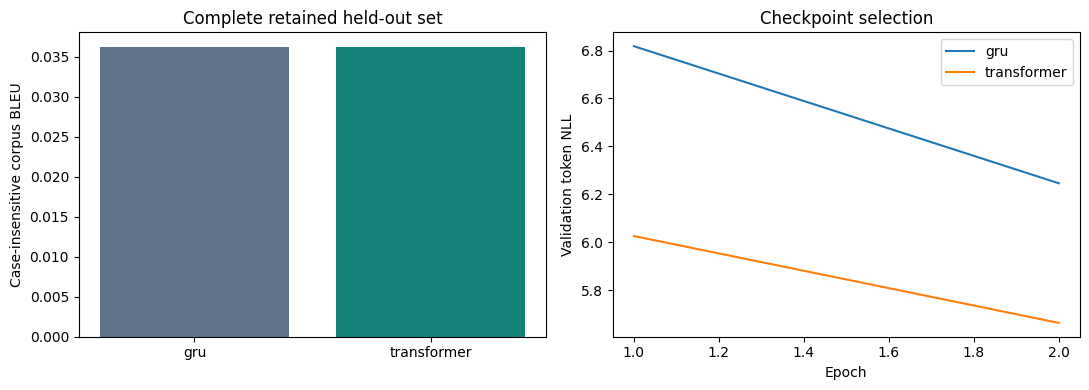

Actual selected counts: {'test': 64, 'validation': 64, 'train': 512}
Same retained pairs, initial embeddings, example order, learning rate and epochs; model capacities and computation differ. Not an isolated causal test of attention.


In [6]:
fig,axes=plt.subplots(1,2,figsize=(11,4))
names=list(report["models"])
axes[0].bar(names,[report["models"][n]["corpus_bleu"] for n in names],color=["#60758a","#138477"])
axes[0].set(ylabel="Case-insensitive corpus BLEU",title="Complete retained held-out set")
for name,result in report["models"].items():
    axes[1].plot([h["epoch"] for h in result["history"]],[h["validation_nll"] for h in result["history"]],label=name)
    print(name,"parameters",result["parameters"],"BLEU signature",result["bleu_signature"],"test samples",result["test_samples"],"reload",result["exact_reload"])
    for example in result["examples"][:3]:print(json.dumps(example,ensure_ascii=False))
axes[1].set(xlabel="Epoch",ylabel="Validation token NLL",title="Checkpoint selection");axes[1].legend()
fig.tight_layout();fig.savefig(OUTPUT/"results.png",dpi=160);plt.show()
print("Actual selected counts:",report["selected_split_counts"])
print(report["comparison"])


## Interpretation and attribution

One seed, short-caption domain, capped vocabularies and six epochs. Parameter counts differ, so an isolated effect of attention is not established. BLEU is a limited automatic metric, not a human translation-quality judgment.

[Multi30k dataset and research references](https://github.com/multi30k/dataset). Text is downloaded from that provider at a pinned revision; the dataset is not bundled or assigned a new license. Concepts studied in the IBM sequence-to-sequence/Transformer courses; no supplied course weights or assessment solutions are included.

Concepts studied through the [IBM AI Engineering Professional Certificate](https://www.coursera.org/professional-certificates/ai-engineer). Original provider conditions remain applicable. Mechanical execution and reload checks do not replace task-specific or human quality evaluation.